# Solver speed comparison: current kernels vs calibrated reference

Run all cells in a fresh Colab GPU runtime after the project's `gpe` folder has
synced to Drive. Both solvers run on the **same GPU, sequentially**, from the same
normalized Gaussian and with the same physical parameters.

- The **current** implementation uses the production `imaginary_step`,
  `ssfmstep_timeV`, and `ssfmstep` functions: two FFT calls per step.
- The **reference** retains the original script's 3D grids, four-FFT split step,
  nonlinear-density evaluation, array exponentials, and normalization expression.
  Its trap, absorber, and rotating drive are calibrated to the current implementation.

The default experiment matches the current stirring notebook: **2,000 imaginary
steps**, then **250** units of stirring and **1,000** units of relaxation. The
effective trap depth is **2**, overriding the config value of 49. The drive's
frequency and amplitude are read from the current kernel (now **0.065**, **0.015**).

There are **no simulation monitors, diagnostic plots, progress bars, or state
saves** during either run. Prints occur only at stage boundaries; the comparison
table and timing plot appear after both runs. Timing results are then saved to Drive.

The first five steps of each stage warm up kernels and FFT plans. They advance
the simulation, but are excluded from the reported mean time per step. GPU events
and synchronized wall time include potential construction and, for imaginary time,
normalization. Initial grid/potential allocation and source compilation checks are
outside the reported timings.

The splitting schemes differ, so this compares implementation speed at matched
settings, not equal numerical error. Both use complex128 states and float64 grids.
The reference retains seven full real 3D coordinate/wavenumber arrays; its memory
requirement is much higher than the current solver's.

In [1]:
import importlib.util
import subprocess
import sys

subprocess.run(["nvidia-smi"],check=True)
if importlib.util.find_spec("cupy") is None:
    subprocess.check_call([sys.executable,"-m","pip","install","-q","cupy-cuda12x[ctk]"])

import cupy as cp
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime, timezone
import csv
import gc
import hashlib
import json
import math
import os
import re
import shutil
import time

cp.cuda.Device(0).use()
gpu_name=cp.cuda.runtime.getDeviceProperties(0)['name']
if isinstance(gpu_name,bytes):
    gpu_name=gpu_name.decode()
print(f"GPU: {gpu_name}; CuPy: {cp.__version__}")


GPU: NVIDIA A100-SXM4-80GB; CuPy: 14.0.1


In [2]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_PROJECT=Path("/content/drive/MyDrive/GPE_simulator")
LOCAL_PROJECT=Path("/content/GPE_simulator")
shutil.copytree(DRIVE_PROJECT/"gpe",LOCAL_PROJECT/"gpe",dirs_exist_ok=True,
                ignore=shutil.ignore_patterns("__pycache__"))
os.chdir(LOCAL_PROJECT)
sys.path.insert(0,str(LOCAL_PROJECT))

from gpe import config as cfg
from gpe.grids import get_grids
from gpe.initial_states import gaussian
from gpe.potentials import box_potential, absorption_potential, get_total_static_potential
from gpe.propagation import imaginary_step, ssfmstep_timeV, ssfmstep
from gpe.helper import get_beta


Mounted at /content/drive


## Matched parameters

Other than the explicit notebook overrides below, settings come from `config.py`.
Changing a value here changes both runs. To shorten the benchmark, reduce the
step count or durations here for both implementations together.

The reference uses the current **maximum-of-walls trap**, **Cartesian linear
absorber**, and **x sin(ωt) + y cos(ωt) drive**. Both evaluate the drive at the
midpoint of each step, disable the momentum cutoff, and retain absorption during
both real-time stages. Neither renormalizes during real time.

In [3]:
N_grids=int(cfg.N_grids)
dt=float(cfg.dt)
imag_dt=float(getattr(cfg,"img_dt",cfg.dt))
sigma=float(getattr(cfg,"sigma",3.0))
beta=float(get_beta(cfg.N_atom,cfg.a))

imag_steps=2000
trap_depth=2.0
stir_duration=250.0
free_duration=1000.0
warmup_steps=5

kernel_source=(LOCAL_PROJECT/"gpe"/"kernels.py").read_text()
drive_call=re.search(r"rotation\(\s*x\s*,\s*y\s*,\s*([^,]+),\s*([^,]+),\s*t\s*\)",kernel_source)
if drive_call is None:
    raise ValueError("This comparison expects the rotation(x,y,omega,A,t) drive in kernels.py.")
omega,amplitude=map(float,drive_call.groups())

assert imag_steps>0 and dt>0 and imag_dt>0 and stir_duration>0 and free_duration>0
assert warmup_steps>=0
stages=[("imaginary",imag_steps,imag_steps*imag_dt,imag_dt),
        ("stirring",math.ceil(stir_duration/dt),stir_duration,dt),
        ("relaxation",math.ceil(free_duration/dt),free_duration,dt)]
parameters=dict(N_grids=N_grids,simulation_range=cfg.simulation_range,
                R=cfg.R,L=cfg.L,wallthickness=cfg.wallthickness,trap_depth=trap_depth,
                r_abs=cfg.r_abs,A_abs=cfg.A_abs,N_atom=cfg.N_atom,a=cfg.a,beta=beta,
                sigma=sigma,dt=dt,imag_dt=imag_dt,imag_steps=imag_steps,
                omega=omega,amplitude=amplitude,stir_duration=stir_duration,
                free_duration=free_duration,momentum_cutoff="disabled",
                trap="maximum of tube and nearest sheet",
                absorber="sum of Cartesian linear ramps",
                drive="A*(x*sin(omega*t)+y*cos(omega*t)); midpoint time")
print(json.dumps(parameters,indent=2))
for stage,count,duration,h in stages:
    print(f"{stage}: {count} steps, dt={h:g}, duration={duration:g}")

GiB=1024**3
reference_persistent_bytes=12*N_grids**3*8
free_bytes,total_bytes=cp.cuda.runtime.memGetInfo()
print(f"Free GPU memory: {free_bytes/GiB:.2f} GiB")
print(f"Reference persistent arrays alone: {reference_persistent_bytes/GiB:.2f} GiB; temporaries and FFT workspace need more")
if reference_persistent_bytes>=free_bytes:
    raise MemoryError("The original reference grids and state cannot fit on this GPU at this resolution.")


{
  "N_grids": 256,
  "simulation_range": 70,
  "R": 25,
  "L": 50,
  "wallthickness": 2,
  "trap_depth": 2.0,
  "r_abs": 5,
  "A_abs": 100,
  "N_atom": 150000,
  "a": 100,
  "beta": 19949.510845106033,
  "sigma": 3.0,
  "dt": 0.01,
  "imag_dt": 0.01,
  "imag_steps": 2000,
  "omega": 0.065,
  "amplitude": 0.015,
  "stir_duration": 250.0,
  "free_duration": 1000.0,
  "momentum_cutoff": "disabled",
  "trap": "maximum of tube and nearest sheet",
  "absorber": "sum of Cartesian linear ramps",
  "drive": "A*(x*sin(omega*t)+y*cos(omega*t)); midpoint time"
}
imaginary: 2000 steps, dt=0.01, duration=20
stirring: 25000 steps, dt=0.01, duration=250
relaxation: 100000 steps, dt=0.01, duration=1000
Free GPU memory: 78.83 GiB
Reference persistent arrays alone: 1.50 GiB; temporaries and FFT workspace need more


## Original reference stepping code

These definitions are copied from `3dsimulations_2_3.py`, with names changed to
avoid collisions and `xp=cp` fixed for GPU execution. The entire exported script
is not imported: its original run loops, settings, monitors, and saves are excluded.

In [4]:
xp=cp

class ReferenceGrid:
    def __init__(self, config):
        self.nx, self.ny, self.nz = int(config['nx']), int(config['ny']), int(config['nz'])
        self.lx, self.ly, self.lz = float(config['lx']), float(config['ly']), float(config['lz'])
        self.dx, self.dy, self.dz = self.lx/self.nx, self.ly/self.ny, self.lz/self.nz

        # Coordinates
        # creating mesh grids for all the x,y,z points
        x = xp.linspace(-self.lx/2, self.lx/2, self.nx, endpoint=False)
        y = xp.linspace(-self.ly/2, self.ly/2, self.ny, endpoint=False)
        z = xp.linspace(-self.lz/2, self.lz/2, self.nz, endpoint=False)
        self.x, self.y, self.z = xp.meshgrid(x, y, z, indexing='ij')

        # Momentum Space
        kx = 2*xp.pi * xp.fft.fftfreq(self.nx, self.dx)
        ky = 2*xp.pi * xp.fft.fftfreq(self.ny, self.dy)
        kz = 2*xp.pi * xp.fft.fftfreq(self.nz, self.dz)
        self.kx, self.ky, self.kz = xp.meshgrid(kx, ky, kz, indexing='ij')
        self.k2 = self.kx**2 + self.ky**2 + self.kz**2

    def fftn(self, psi): return xp.fft.fftn(psi) # this is just the xp's F.T.
    def ifftn(self, psi): return xp.fft.ifftn(psi)

class ReferencePropagator:
    def __init__(self, grid):
        self.grid = grid
        # to define the propagator class, we need to define the grid at first

    def step_ssfm(self, psi, V_total, dt):
        """Split-Step Fourier Method for time evolution"""
        # 1. Half-step Dispersion (Kinetic)
        psi_k = self.grid.fftn(psi)
        psi_k *= xp.exp(-0.5j * self.grid.k2 * dt)
        psi = self.grid.ifftn(psi_k)

        # 2. Full-step Potential
        psi *= xp.exp(-1j * V_total * dt)

        # 3. Half-step Dispersion (Kinetic)
        psi_k = self.grid.fftn(psi)
        psi_k *= xp.exp(-0.5j * self.grid.k2 * dt)
        psi = self.grid.ifftn(psi_k)

        return psi

def reference_nonlinearity(psi, beta):
    return beta * xp.abs(psi)**2

def reference_normalize(psi, grid):
  # caution that normalisation step is only used in the imaginary time search
    dvol = grid.dx * grid.dy * grid.dz
    norm = xp.sqrt(xp.sum(xp.abs(psi)**2) * dvol)
    return psi / norm


In [5]:
def make_solver(name,n):
    x,k=get_grids(n,cfg.simulation_range)
    psi=gaussian(x,sigma)
    box=box_potential(x,cfg.R,cfg.L,cfg.wallthickness,trap_depth)
    absorber=absorption_potential(cfg.r_abs,cfg.A_abs,x,cfg.simulation_range)

    if name=="current":
        V_static=get_total_static_potential(box,absorber)

        def imaginary(psi,h,t):
            return imaginary_step(psi,box,beta,k,h,n,x)

        def stirring(psi,h,t):
            return ssfmstep_timeV(psi,V_static,beta,k,x,h,n,float("inf"),t)

        def relaxation(psi,h,t):
            return ssfmstep(psi,V_static,beta,k,h,n)
    else:
        grid=ReferenceGrid(dict(nx=n,ny=n,nz=n,lx=cfg.simulation_range,
                                ly=cfg.simulation_range,lz=cfg.simulation_range))
        propagator=ReferencePropagator(grid)
        V_abs=-1j*absorber

        def imaginary(psi,h,t):
            V_nonlinear=reference_nonlinearity(psi,beta)
            psi=propagator.step_ssfm(psi,box+V_nonlinear,-1j*h)
            return reference_normalize(psi,grid)

        def stirring(psi,h,t):
            t_mid=t+h/2
            V_stir=amplitude*(grid.x*xp.sin(omega*t_mid)+grid.y*xp.cos(omega*t_mid))
            V_nonlinear=reference_nonlinearity(psi,beta)
            V_total=box+V_stir+V_nonlinear+V_abs
            return propagator.step_ssfm(psi,V_total,h)

        def relaxation(psi,h,t):
            V_nonlinear=reference_nonlinearity(psi,beta)
            V_total=box+V_nonlinear+V_abs
            return propagator.step_ssfm(psi,V_total,h)

    return psi,dict(imaginary=imaginary,stirring=stirring,relaxation=relaxation)


def release_gpu_cache():
    gc.collect()
    cp.fft.config.get_plan_cache().clear()
    cp.get_default_memory_pool().free_all_blocks()


## Small GPU check before timing

Compare each method's three step functions against its own NumPy formula on an
8³ grid. This checks parameter matching, drive timing, absorption, and the current
CUDA header before the full allocation. Equality between the two different
splitting schemes is not required.

In [6]:
def check_small_steps():
    n=8
    length=cfg.simulation_range
    x=np.linspace(-length/2,length/2,n,endpoint=False)
    k=2*np.pi*np.fft.fftfreq(n,length/n)
    X,Y,Z=x[:,None,None],x[None,:,None],x[None,None,:]
    k2=k[:,None,None]**2+k[None,:,None]**2+k[None,None,:]**2
    box=trap_depth*np.maximum(
        np.exp(-(np.sqrt(X**2+Y**2)-cfg.R)**2/(2*cfg.wallthickness**2)),
        np.exp(-(np.abs(Z)-cfg.L/2)**2/(2*cfg.wallthickness**2)))
    absorber=cfg.A_abs*sum(np.maximum(cfg.r_abs-(axis+length/2),0)
                          +np.maximum(cfg.r_abs-(length/2-axis),0) for axis in (X,Y,Z))
    rng=np.random.default_rng(42)
    state=rng.normal(size=(n,n,n))+1j*rng.normal(size=(n,n,n))
    state/=np.sqrt(np.sum(abs(state)**2)*(length/n)**3)
    for name in ("current","reference"):
        seed,steppers=make_solver(name,n)
        for stage in ("imaginary","stirring","relaxation"):
            h=imag_dt if stage=="imaginary" else dt
            t=0.37
            coefficient=-1 if stage=="imaginary" else -1j
            V=box if stage=="imaginary" else box-1j*absorber
            if stage=="stirring":
                tm=t+h/2
                V=V+amplitude*(X*np.sin(omega*tm)+Y*np.cos(omega*tm))
            if name=="current":
                expected=state*np.exp(coefficient*h/2*(V+beta*abs(state)**2))
                expected=np.fft.ifftn(np.fft.fftn(expected)*np.exp(coefficient*h*k2))
                expected*=np.exp(coefficient*h/2*(V+beta*abs(expected)**2))
            else:
                half=np.exp(coefficient*h/2*k2)
                expected=np.fft.ifftn(np.fft.fftn(state)*half)
                expected*=np.exp(coefficient*h*(V+beta*abs(state)**2))
                expected=np.fft.ifftn(np.fft.fftn(expected)*half)
            if stage=="imaginary":
                expected/=np.sqrt(np.sum(abs(expected)**2)*(length/n)**3)
            actual=steppers[stage](cp.asarray(state.copy()),h,t)
            np.testing.assert_allclose(cp.asnumpy(actual),expected,rtol=1e-10,atol=1e-12)

check_small_steps()
release_gpu_cache()
print("Both methods passed their small GPU/NumPy checks.")


Both methods passed their small GPU/NumPy checks.


## Run both experiments without monitors

Each method starts from a fresh identical Gaussian. Every stage runs for its full
configured duration, including warm-up steps. The time resets to zero at the
beginning of stirring. A shortened final step handles durations not divisible by dt.

Timings are phase averages, not medians of individually synchronized steps.
There is no per-step synchronization, printing, plotting, diagnostic reduction,
or disk I/O in the timed loops. Normalization remains part of imaginary evolution.

In [7]:
def run_solver(name):
    print(f"Allocating {name}: {N_grids}³...",flush=True)
    psi,steppers=make_solver(name,N_grids)
    cp.cuda.get_current_stream().synchronize()
    cp.get_default_memory_pool().free_all_blocks()
    rows=[]
    for stage,count,duration,h in stages:
        print(f"{name}: {stage}, {count} steps...",flush=True)
        step=steppers.pop(stage)
        warm_count=min(warmup_steps,count-1)
        warm_start=time.perf_counter()
        for i in range(warm_count):
            psi=step(psi,min(h,duration-i*h),i*h)
        cp.cuda.get_current_stream().synchronize()
        warm_wall_s=time.perf_counter()-warm_start

        start_event,end_event=cp.cuda.Event(),cp.cuda.Event()
        wall_start=time.perf_counter()
        start_event.record()
        for i in range(warm_count,count):
            psi=step(psi,min(h,duration-i*h),i*h)
        end_event.record()
        end_event.synchronize()
        timed_wall_s=time.perf_counter()-wall_start
        gpu_ms=cp.cuda.get_elapsed_time(start_event,end_event)
        measured_steps=count-warm_count
        row=dict(implementation=name,stage=stage,steps=count,duration=duration,dt=h,
                 warmup_steps=warm_count,measured_steps=measured_steps,
                 gpu_ms_per_step=gpu_ms/measured_steps,wall_ms_per_step=1000*timed_wall_s/measured_steps,
                 timed_gpu_s=gpu_ms/1000,timed_wall_s=timed_wall_s,warmup_wall_s=warm_wall_s)
        rows.append(row)
        del step
        print(f"  {row['gpu_ms_per_step']:.3f} GPU ms/step; {row['wall_ms_per_step']:.3f} wall ms/step",flush=True)
    return rows


In [8]:
results=[]
for name in ("current","reference"):
    release_gpu_cache()
    results.extend(run_solver(name))
    release_gpu_cache()
print("Both runs finished.")


Allocating current: 256³...
current: imaginary, 2000 steps...
  3.906 GPU ms/step; 3.906 wall ms/step
current: stirring, 25000 steps...
  3.625 GPU ms/step; 3.625 wall ms/step
current: relaxation, 100000 steps...
  3.564 GPU ms/step; 3.564 wall ms/step
Allocating reference: 256³...
reference: imaginary, 2000 steps...
  10.568 GPU ms/step; 10.568 wall ms/step
reference: stirring, 25000 steps...
  10.978 GPU ms/step; 10.978 wall ms/step
reference: relaxation, 100000 steps...
  10.033 GPU ms/step; 10.033 wall ms/step
Both runs finished.


Stage           Current GPU    Reference GPU    Ratio ref/current
imaginary          3.906 ms        10.568 ms                2.71x
stirring           3.625 ms        10.978 ms                3.03x
relaxation         3.564 ms        10.033 ms                2.82x
A ratio above 1 means the current implementation is faster.


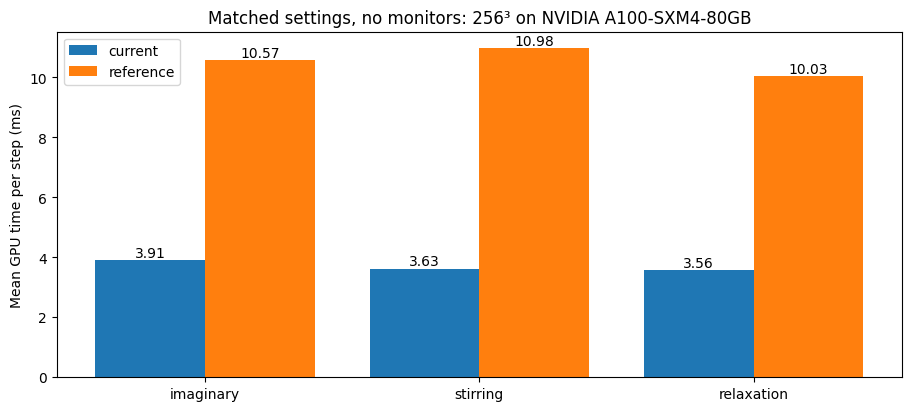

In [9]:
print(f"{'Stage':12s} {'Current GPU':>14s} {'Reference GPU':>16s} {'Ratio ref/current':>20s}")
ratios={}
for stage,_,_,_ in stages:
    current=next(row for row in results if row['implementation']=="current" and row['stage']==stage)
    reference=next(row for row in results if row['implementation']=="reference" and row['stage']==stage)
    ratio=reference['gpu_ms_per_step']/current['gpu_ms_per_step']
    ratios[stage]=ratio
    print(f"{stage:12s} {current['gpu_ms_per_step']:11.3f} ms {reference['gpu_ms_per_step']:13.3f} ms {ratio:19.2f}x")
print("A ratio above 1 means the current implementation is faster.")

labels=[stage for stage,_,_,_ in stages]
positions=np.arange(len(labels))
fig,ax=plt.subplots(figsize=(9,4),layout="constrained")
for name,offset in (("current",-.2),("reference",.2)):
    times=[next(row['gpu_ms_per_step'] for row in results
                if row['implementation']==name and row['stage']==stage) for stage in labels]
    bars=ax.bar(positions+offset,times,width=.4,label=name)
    ax.bar_label(bars,fmt="%.2f")
ax.set(xticks=positions,xticklabels=labels,ylabel="Mean GPU time per step (ms)",
       title=f"Matched settings, no monitors: {N_grids}³ on {gpu_name}")
ax.legend()
plt.show()
plt.close(fig)


In [10]:
run_id=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")+f"_N{N_grids}"
OUTPUT_DIR=DRIVE_PROJECT/"benchmark_results"/"solver_comparison"/run_id
OUTPUT_DIR.mkdir(parents=True)
with (OUTPUT_DIR/"timings.csv").open("w",newline="") as file:
    writer=csv.DictWriter(file,fieldnames=list(results[0]))
    writer.writeheader()
    writer.writerows(results)
metadata=dict(parameters=parameters,gpu=gpu_name,cupy=cp.__version__,numpy=np.__version__,
              cuda_runtime=cp.cuda.runtime.runtimeGetVersion(),
              cuda_driver=cp.cuda.runtime.driverGetVersion(),warmup_steps=warmup_steps,
              reference_script="3dsimulations_2_3.py",reference_source_sha256="1f0c3ea776d22d4605e80e65f937334ad4cdd48817024513437a6de0888179e3",
              source_sha256={p.name:hashlib.sha256(p.read_bytes()).hexdigest()
                             for p in sorted((LOCAL_PROJECT/"gpe").iterdir()) if p.suffix in (".py",".cuh")},
              gpu_time_ratio_reference_over_current=ratios,results=results)
(OUTPUT_DIR/"run_metadata.json").write_text(json.dumps(metadata,indent=2)+"\n")
print(f"Timing results saved to {OUTPUT_DIR}")


Timing results saved to /content/drive/MyDrive/GPE_simulator/benchmark_results/solver_comparison/20261010T125600063923Z_N256
